# Poids des attributs dans le walk index — urbain vs non urbain

Ce notebook analyse, **layer par layer** (`_urban` / `_non_urban`), le poids de chaque attribut :
- au sein de sa **classe** (Attractivité, Commodité, Infrastructure, Sécurité),
- au sein du **walk index** de la layer.

Chaque layer est analysée avec **ses propres colonnes** (`*_urban` ou `*_non_urban`) et **ses propres poids** (Excel `attributs_info_walk_urbain.xlsx` / `attributs_info_walk_non_urbain.xlsx`). Aucune valeur de l'autre type n'est mélangée.

| # | Métrique | Question |
|---|---|---|
| 1 | Distribution (part de 0, part de 1, IQR, P5–P95, skew) | L'attribut a-t-il une plage de variation utile ? |
| 2 | Contribution moyenne $c_a = \tilde w_a\,x_a$ | De quoi est fait le score d'un carreau typique ? |
| 3 | Décomposition de variance $\mathrm{Cov}(c_a, Y)/\mathrm{Var}(Y)$ | Qu'est-ce qui différencie les carreaux entre eux ? |
| 4 | Déficit $\tilde w_a\,(1-x_a)$ | Qu'est-ce qui fait perdre des points ? |
| 5 | Corrélation de Spearman | Lien monotone attribut ↔ classe / indice |

**Convention** : les attributs du gpkg sont supposés déjà normalisés dans [0, 1] et orientés « plus = mieux » (les attributs *défavorables* comme `bruit`, `accident` sont déjà inversés — vérifié dans la cellule de contrôle).

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.3f}".format)

# ------------------------------------------------------------------
# CONFIG — adapter les chemins à ton arborescence
# ------------------------------------------------------------------
GPKG_PATH = Path("/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/output/walk/GG/step-3_geo_weighted/step3_aggregated_index_carreau200.gpkg")
LAYERS = {
    "urban": {
        "layer": "step3_aggregated_index_carreau200_urban",
        "suffix": "urban",
        "excel": Path("/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/input/attributs/attributs_info_walk_urbain.xlsx"),
    },
    "non_urban": {
        "layer": "step3_aggregated_index_carreau200_non_urban",
        "suffix": "non_urban",
        "excel": Path("/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/input/attributs/attributs_info_walk_non_urbain.xlsx"),
    },
}
CLASSES = ["Attractivité", "Commodité", "Infrastructure", "Sécurité"]
OUT_DIR = Path("/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/output/walk/GG/etude_stat")
OUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"urban": "#c0392b", "non_urban": "#27ae60"}

## 0. Chargement des layers et des poids

- Lecture des **attributs** de chaque layer sans la géométrie (rapide).
- Lecture des poids depuis l'onglet `attributs_info` :
  - `class_weight` → poids de l'attribut **dans sa classe**,
  - `initial_weight` → poids de l'attribut **dans le walk index** (moyenne pondérée sur tous les attributs).
- Seuls les attributs présents dans le gpkg **et** de poids > 0 entrent dans les métriques 2 à 4. Les attributs à poids 0 restent visibles dans la métrique 1 (pour info).
- Contrôle NaN : toute ligne avec un NaN sur une colonne utilisée est signalée puis exclue.

In [2]:
def load_weights(xlsx_path, available_cols):
    w = pd.read_excel(xlsx_path, sheet_name="attributs_info")
    w = w[w["attribute"].isin(available_cols)].copy()
    w = w[["Class", "attribute", "initial_weight", "class_weight", "impact_attribut"]]
    w[["initial_weight", "class_weight"]] = w[["initial_weight", "class_weight"]].fillna(0.0).astype(float)
    return w.drop_duplicates("attribute").set_index("attribute")


def load_layer(key):
    cfg = LAYERS[key]
    sfx = cfg["suffix"]
    gdf = gpd.read_file(GPKG_PATH, layer=cfg["layer"], ignore_geometry=True)
    weights = load_weights(cfg["excel"], gdf.columns)

    class_cols = {k: f"{k}_{sfx}" for k in CLASSES}
    index_col = f"walk_index_{sfx}"
    attrs = list(weights.index)
    used = attrs + list(class_cols.values()) + [index_col]

    missing = [c for c in used if c not in gdf.columns]
    assert not missing, f"[{key}] colonnes absentes : {missing}"

    df = gdf[["GRID_ID"] + used].copy()
    df[used] = df[used].apply(pd.to_numeric, errors="coerce")
    nan_rows = df[used].isna().any(axis=1)
    print(f"[{key}] {len(df):,} carreaux | lignes avec NaN : {nan_rows.sum():,}")
    if nan_rows.any():
        print("   NaN par colonne :", df[used].isna().sum()[lambda s: s > 0].to_dict())
    df = df.loc[~nan_rows].reset_index(drop=True)

    return {"df": df, "weights": weights, "attrs": attrs,
            "class_cols": class_cols, "index_col": index_col}


data = {k: load_layer(k) for k in LAYERS}

[urban] 21,500 carreaux | lignes avec NaN : 0
[non_urban] 26,396 carreaux | lignes avec NaN : 0


In [3]:
# Tableau comparatif des poids
wcmp = pd.concat({k: d["weights"][["Class", "class_weight", "initial_weight"]] for k, d in data.items()}, axis=1)
wcmp.insert(0, "Class", wcmp[("urban", "Class")].fillna(wcmp[("non_urban", "Class")]))
wcmp = wcmp.drop(columns=[("urban", "Class"), ("non_urban", "Class")])
wcmp = wcmp.sort_values("Class")
wcmp

Class        urban                   non_urban               
                                             class_weight initial_weight class_weight initial_weight
attribute                                                                                           
lac_cours_deau                  Attractivité        0.500          0.500        0.500          0.500
fontaine                        Attractivité        0.500          0.500        0.000          0.000
espaces_ouverts                 Attractivité        0.500          0.500        0.000          0.000
rez_actif                       Attractivité        0.500          0.500        0.000          0.000
tp                              Attractivité        0.500          0.500        0.000          0.000
amenite                         Attractivité        0.500          0.500        0.000          0.000
air                                Commodité        0.500          0.500        0.500          0.500
toilette                           Commodité        0.500          0.500        0.000          0.000
canopee                            Commodité        0.500          0.500        0.500          0.500
banc                               Commodité        0.500          0.500        0.500          0.500
conflit_md                         Commodité        0.500          0.500        0.000          0.000
temperature                        Commodité        0.500          0.500        0.500          0.500
bruit                              Commodité        0.500          0.500        0.500          0.500
environnement_ouvert_naturel       Commodité        0.000          0.000        0.000          0.000
connectivite                  Infrastructure        0.500          0.500        0.000          0.000
traversees                    Infrastructure        0.500          0.500        0.000          0.000
chemin                        Infrastructure        0.000          0.000        0.500          0.500
pente                         Infrastructure        0.500          0.500        0.500          0.500
vitesse                             Sécurité        0.500          0.500        0.500          0.500
accident                            Sécurité        0.500          0.500        0.500          0.500
charge                              Sécurité        0.500          0.500        0.500          0.500
zone_apaisee                        Sécurité        0.000          0.000        0.000          0.000
zone_pietonne                       Sécurité        0.000          0.000        0.000          0.000
eclairage                           Sécurité        0.500          0.500        0.000          0.000

In [4]:
# Contrôle d'orientation : un attribut 'defavorable' devrait déjà être inversé (corrélation > 0 avec sa classe)
rows = []
for k, d in data.items():
    df, w = d["df"], d["weights"]
    for a, r in w[w["class_weight"] > 0].iterrows():
        rho = stats.spearmanr(df[a], df[d["class_cols"][r["Class"]]]).statistic
        rows.append((k, a, r["impact_attribut"], rho))
chk = pd.DataFrame(rows, columns=["layer", "attribut", "impact", "spearman_avec_classe"])
print("Attributs défavorables avec corrélation négative à leur classe (non inversés ?) :")
chk[(chk.impact == "defavorable") & (chk.spearman_avec_classe < 0)]

Attributs défavorables avec corrélation négative à leur classe (non inversés ?) :


,layer,attribut,impact,spearman_avec_classe


### Reconstruction et fidélité

On reconstruit les scores à partir des attributs du carreau et des poids Excel :

$$\hat C_k = \frac{\sum_{a\in k} w^{class}_a\,x_a}{\sum_{a\in k} w^{class}_a}, \qquad \hat I = \frac{\sum_a w^{init}_a\,x_a}{\sum_a w^{init}_a}$$

Si le step3 calcule l'indice **par segment avant d'agréger au carreau** (ou renormalise quand un attribut `keep_nan` manque), la reconstruction ne sera pas exacte. Le tableau ci-dessous mesure l'écart. Les métriques 3 utilisent les **vraies valeurs du gpkg** comme cible et isolent l'écart dans un terme *résidu*, donc la décomposition reste exacte.

In [5]:
def build_contributions(d):
    df, w = d["df"], d["weights"]
    out = {}
    # dans la classe
    for k in CLASSES:
        wk = w[(w["Class"] == k) & (w["class_weight"] > 0)]["class_weight"]
        out[("class", k)] = (df[wk.index] * (wk / wk.sum()).values) if len(wk) else pd.DataFrame(index=df.index)
    # dans l'indice
    wi = w[w["initial_weight"] > 0]["initial_weight"]
    out[("index", None)] = df[wi.index] * (wi / wi.sum()).values
    return out


def fidelity(y, yhat):
    r = np.corrcoef(y, yhat)[0, 1]
    return {"pearson_r": r, "R2": 1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "MAE": (y - yhat).abs().mean(), "biais_moyen (gpkg - reconstr.)": (y - yhat).mean()}


for k, d in data.items():
    d["contrib"] = build_contributions(d)

fid = []
for k, d in data.items():
    for c in CLASSES:
        cb = d["contrib"][("class", c)]
        if cb.shape[1]:
            fid.append({"layer": k, "cible": c, **fidelity(d["df"][d["class_cols"][c]], cb.sum(axis=1))})
    fid.append({"layer": k, "cible": "walk_index", **fidelity(d["df"][d["index_col"]], d["contrib"][("index", None)].sum(axis=1))})
fid = pd.DataFrame(fid).set_index(["layer", "cible"])
fid

pearson_r     R2   MAE  biais_moyen (gpkg - reconstr.)
layer     cible                                                                 
urban     Attractivité        0.987  0.974 0.002                           0.001
          Commodité           0.987 -0.713 0.124                           0.123
          Infrastructure      0.945  0.892 0.010                          -0.002
          Sécurité            0.973  0.945 0.007                          -0.002
          walk_index          0.966  0.377 0.038                           0.037
non_urban Attractivité        0.937  0.878 0.006                           0.002
          Commodité           0.979 -1.768 0.158                           0.158
          Infrastructure      0.918  0.832 0.024                           0.013
          Sécurité            0.942  0.882 0.013                           0.006
          walk_index          0.930 -0.568 0.109                           0.109

In [6]:
# Diagnostic : coefficients OLS bruts (non renormalisés) de chaque score du gpkg sur ses attributs.
# Pour une moyenne pondérée, la somme des coefficients doit valoir ~1 et la constante ~0.
# Une somme nettement > 1 signifie que le step3 divise par moins que la somme des poids (score gonflé).
rows = []
for k, d in data.items():
    targets = [(c, d["class_cols"][c], d["contrib"][("class", c)].columns) for c in CLASSES] + \
              [("walk_index", d["index_col"], d["contrib"][("index", None)].columns)]
    for name, col, attrs in targets:
        if not len(attrs):
            continue
        X = d["df"][attrs].values; y = d["df"][col].values
        b, *_ = np.linalg.lstsq(np.c_[X, np.ones(len(X))], y, rcond=None)
        rows.append({"layer": k, "cible": name, "n_attributs": len(attrs),
                     "somme_coefs": b[:-1].sum(), "constante": b[-1]})
pd.DataFrame(rows).set_index(["layer", "cible"])

n_attributs  somme_coefs  constante
layer     cible                                              
urban     Attractivité              6        0.990      0.001
          Commodité                 7        1.367     -0.014
          Infrastructure            3        0.989      0.010
          Sécurité                  4        0.991      0.003
          walk_index               20        1.242     -0.044
non_urban Attractivité              1        1.018      0.001
          Commodité                 5        1.328      0.015
          Infrastructure            2        0.943      0.059
          Sécurité                  3        0.905      0.097
          walk_index               11        1.105      0.064

In [7]:
# Poids effectifs des classes dans l'indice (implicites via initial_weight)
cls_w = pd.DataFrame({
    k: d["weights"][d["weights"]["initial_weight"] > 0].groupby("Class")["initial_weight"].sum()
       .pipe(lambda s: s / s.sum()).reindex(CLASSES)
    for k, d in data.items()
})
cls_w.columns.name = "poids de la classe dans l'indice"
cls_w

poids de la classe dans l'indice,urban,non_urban
Class,,
Attractivité,0.300,0.091
Commodité,0.350,0.455
Infrastructure,0.150,0.182
Sécurité,0.200,0.273


## 1. Distribution des attributs

- `%zero` / `%one` : part des carreaux à 0 ou saturés à 1. Un attribut avec 90 % de zéros ne peut quasiment pas différencier les carreaux.
- `IQR`, `P5–P95` : plage de variation utile.
- `skew` : asymétrie (forte valeur positive = beaucoup de 0 et quelques pics → signe d'une normalisation par le max écrasée par des outliers).

In [8]:
def describe_attrs(d, include_zero_weight=True):
    df, w = d["df"], d["weights"]
    attrs = w.index if include_zero_weight else w[w["initial_weight"] > 0].index
    X = df[attrs]
    res = pd.DataFrame({
        "classe": w.loc[attrs, "Class"],
        "poids_index": w.loc[attrs, "initial_weight"],
        "mean": X.mean(), "median": X.median(), "std": X.std(),
        "%zero": (X == 0).mean() * 100, "%one": (X == 1).mean() * 100,
        "IQR": X.quantile(.75) - X.quantile(.25),
        "P5-P95": X.quantile(.95) - X.quantile(.05),
        "skew": X.skew(),
    })
    return res

desc = {k: describe_attrs(d) for k, d in data.items()}
desc_cmp = pd.concat(desc, axis=1).sort_values(("urban", "classe"))
desc_cmp

urban                                                                        non_urban                                                                 
                                      classe poids_index  mean median   std  %zero   %one   IQR P5-P95   skew          classe poids_index  mean median   std  %zero   %one   IQR P5-P95   skew
lac_cours_deau                  Attractivité       0.500 0.041  0.000 0.159 89.386  0.851 0.000  0.341  4.445    Attractivité       0.500 0.029  0.000 0.142 94.367  0.932 0.000  0.081  5.511
fontaine                        Attractivité       0.500 0.011  0.000 0.051 92.135  0.005 0.000  0.067  6.653    Attractivité       0.000 0.001  0.000 0.019 98.917  0.000 0.000  0.000 16.939
espaces_ouverts                 Attractivité       0.500 0.018  0.000 0.091 91.837  0.153 0.000  0.097  6.839    Attractivité       0.000 0.004  0.000 0.052 98.928  0.117 0.000  0.000 15.574
rez_actif                       Attractivité       0.500 0.012  0.000 0.064 90.200  0.005 0.000  0.066  8.450    Attractivité       0.000 0.000  0.000 0.009 99.409  0.000 0.000  0.000 34.634
tp                              Attractivité       0.500 0.186  0.000 0.329 66.660  3.949 0.233  0.983  1.524    Attractivité       0.000 0.021  0.000 0.118 95.317  0.356 0.000  0.000  6.420
amenite                         Attractivité       0.500 0.020  0.000 0.086 90.060  0.000 0.000  0.147  5.626    Attractivité       0.000 0.001  0.000 0.013 99.553  0.000 0.000  0.000 27.984
air                                Commodité       0.500 0.199  0.210 0.071  0.112  0.000 0.083  0.245 -0.411       Commodité       0.500 0.241  0.246 0.072  0.008  0.023 0.088  0.231 -0.064
toilette                           Commodité       0.500 0.001  0.000 0.011 98.572  0.005 0.000  0.000 43.266       Commodité       0.000 0.000  0.000 0.006 99.833  0.000 0.000  0.000 73.831
canopee                            Commodité       0.500 0.673  0.748 0.257  0.195  0.460 0.380  0.813 -0.839       Commodité       0.500 0.892  0.943 0.146  0.144  4.550 0.081  0.424 -3.092
banc                               Commodité       0.500 0.011  0.000 0.050 91.298  0.009 0.000  0.069  7.635       Commodité       0.500 0.003  0.000 0.034 98.208  0.019 0.000  0.000 15.036
conflit_md                         Commodité       0.500 0.820  0.843 0.146  0.014  9.688 0.209  0.462 -0.866       Commodité       0.000 0.916  0.960 0.104  0.000 35.642 0.141  0.298 -1.428
temperature                        Commodité       0.500 0.081  0.049 0.092 17.395  0.000 0.126  0.273  1.268       Commodité       0.500 0.205  0.215 0.139  7.391  0.008 0.246  0.416  0.005
bruit                              Commodité       0.500 0.862  0.966 0.187  0.005 35.112 0.236  0.531 -1.441       Commodité       0.500 0.934  1.000 0.158  0.015 70.435 0.009  0.455 -2.792
environnement_ouvert_naturel       Commodité       0.000 0.310  0.233 0.293 15.991  0.084 0.502  0.870  0.637       Commodité       0.000 0.355  0.246 0.361 33.270  0.220 0.706  0.946  0.418
connectivite                  Infrastructure       0.500 0.100  0.086 0.059  0.265  0.000 0.052  0.164  2.905  Infrastructure       0.000 0.070  0.063 0.025  0.258  0.000 0.018  0.065  5.978
traversees                    Infrastructure       0.500 0.694  0.700 0.206  0.553 12.084 0.248  0.700 -0.489  Infrastructure       0.000 0.850  1.000 0.266  2.947 64.608 0.214  0.712 -1.790
chemin                        Infrastructure       0.000 0.346  0.156 0.392 38.051 15.633 0.708  1.000  0.660  Infrastructure       0.500 0.827  1.000 0.326  8.388 69.749 0.177  1.000 -1.722
pente                         Infrastructure       0.500 0.657  0.693 0.185  0.098  0.014 0.259  0.598 -0.790  Infrastructure       0.500 0.643  0.686 0.210  0.295  0.019 0.300  0.671 -0.791
vitesse                             Sécurité       0.500 0.440  0.400 0.248  4.102  1.874 0.319  0.862  0.345        Sécurité       0.500 0.707  0.800 0.296  5.664 17.014 0.302  1.000 -1.219
accident                    

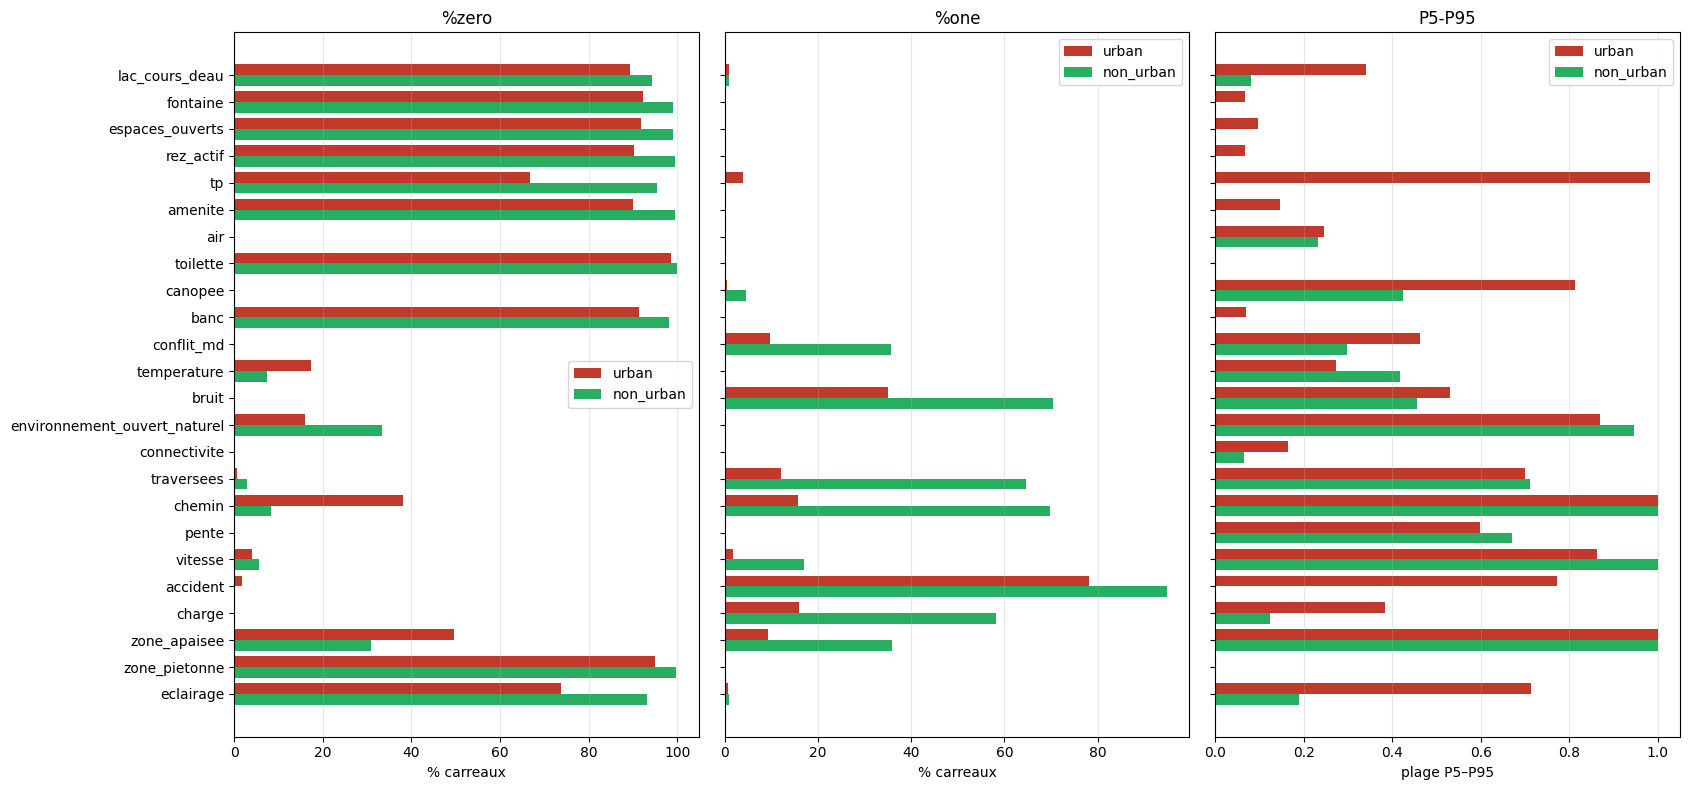

In [9]:
def grouped_barh(table, title, xlabel, ax=None, order=None):
    """table : index = attributs, colonnes = layers."""
    order = order if order is not None else table.index
    table = table.reindex(order)
    ax = ax or plt.gca()
    y = np.arange(len(table)); h = 0.4
    for i, k in enumerate(table.columns):
        ax.barh(y + (i - 0.5) * h, table[k].values, height=h, label=k, color=COLORS.get(k))
    ax.set_yticks(y, table.index); ax.invert_yaxis()
    ax.set_title(title); ax.set_xlabel(xlabel); ax.legend(); ax.grid(axis="x", alpha=.3)
    return ax

order_all = desc_cmp.index
fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)
for ax, m, lab in zip(axes, ["%zero", "%one", "P5-P95"], ["% carreaux", "% carreaux", "plage P5–P95"]):
    grouped_barh(pd.DataFrame({k: desc[k][m] for k in data}), m, lab, ax=ax, order=order_all)
plt.tight_layout(); plt.savefig(OUT_DIR / "1_distribution.png", dpi=150); plt.show()

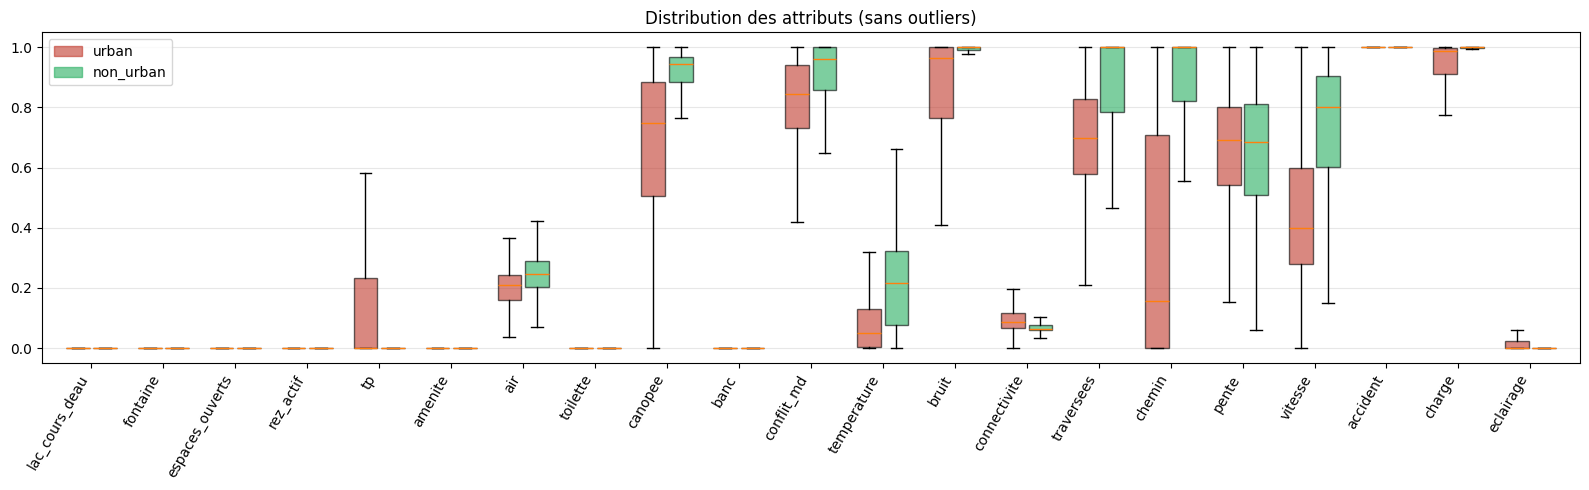

In [10]:
# Boxplots côte à côte (attributs entrant dans l'indice d'au moins une layer)
attrs_box = [a for a in order_all if any(data[k]["weights"].loc[a, "initial_weight"] > 0 for k in data if a in data[k]["weights"].index)]
fig, ax = plt.subplots(figsize=(16, 5))
pos = np.arange(len(attrs_box))
for i, k in enumerate(data):
    vals = [data[k]["df"][a].values for a in attrs_box]
    bp = ax.boxplot(vals, positions=pos + (i - .5) * .38, widths=.33, patch_artist=True, showfliers=False)
    for b in bp["boxes"]: b.set_facecolor(COLORS[k]); b.set_alpha(.6)
ax.set_xticks(pos, attrs_box, rotation=60, ha="right")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[k], alpha=.6) for k in data], list(data))
ax.set_title("Distribution des attributs (sans outliers)"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "1_boxplots.png", dpi=150); plt.show()

## 2. Contribution moyenne

$c_a = \tilde w_a \cdot x_a$ avec $\tilde w_a$ le poids normalisé (dans la classe ou dans l'indice). La part $\overline{c_a} / \sum_b \overline{c_b}$ dit de quoi est composé le score moyen.

À comparer au **poids nominal** $\tilde w_a$ : un attribut qui pèse 17 % nominalement mais 1 % du score moyen est un attribut « mort » (presque toujours à 0).

In [11]:
def mean_contrib(contrib_df):
    m = contrib_df.mean()
    return pd.DataFrame({"contrib_moy": m, "part_%": m / m.sum() * 100})

def nominal_share(d, level, cls=None):
    w = d["weights"]
    if level == "index":
        s = w[w["initial_weight"] > 0]["initial_weight"]
    else:
        s = w[(w["Class"] == cls) & (w["class_weight"] > 0)]["class_weight"]
    return s / s.sum() * 100

# --- dans l'indice
rows = {}
for k, d in data.items():
    t = mean_contrib(d["contrib"][("index", None)])
    t["poids_nominal_%"] = nominal_share(d, "index")
    t["classe"] = d["weights"].loc[t.index, "Class"]
    rows[k] = t
m2_index = pd.concat(rows, axis=1)
m2_index

urban                                          non_urban                                       
                contrib_moy part_% poids_nominal_%          classe contrib_moy part_% poids_nominal_%          classe
lac_cours_deau        0.002  0.613           5.000    Attractivité       0.003  0.445           9.091    Attractivité
fontaine              0.001  0.158           5.000    Attractivité         NaN    NaN             NaN             NaN
espaces_ouverts       0.001  0.271           5.000    Attractivité         NaN    NaN             NaN             NaN
rez_actif             0.001  0.181           5.000    Attractivité         NaN    NaN             NaN             NaN
tp                    0.009  2.753           5.000    Attractivité         NaN    NaN             NaN             NaN
amenite               0.001  0.298           5.000    Attractivité         NaN    NaN             NaN             NaN
bruit                 0.043 12.744           5.000       Commodité       0.085 14.488           9.091       Commodité
temperature           0.004  1.201           5.000       Commodité       0.019  3.188           9.091       Commodité
conflit_md            0.041 12.122           5.000       Commodité         NaN    NaN             NaN             NaN
canopee               0.034  9.948           5.000       Commodité       0.081 13.838           9.091       Commodité
banc                  0.001  0.156           5.000       Commodité       0.000  0.053           9.091       Commodité
toilette              0.000  0.012           5.000       Commodité         NaN    NaN             NaN             NaN
air                   0.010  2.939           5.000       Commodité       0.022  3.745           9.091       Commodité
connectivite          0.005  1.484           5.000  Infrastructure         NaN    NaN             NaN             NaN
traversees            0.035 10.262           5.000  Infrastructure         NaN    NaN             NaN             NaN
pente                 0.033  9.715           5.000  Infrastructure       0.058  9.973           9.091  Infrastructure
accident              0.045 13.390           5.000        Sécurité       0.090 15.287           9.091        Sécurité
charge                0.046 13.628           5.000        Sécurité       0.089 15.181           9.091        Sécurité
vitesse               0.022  6.499           5.000        Sécurité       0.064 10.971           9.091        Sécurité
eclairage             0.006  1.626           5.000        Sécurité         NaN    NaN             NaN             NaN
chemin                  NaN    NaN             NaN             NaN       0.075 12.831           9.091  Infrastructure

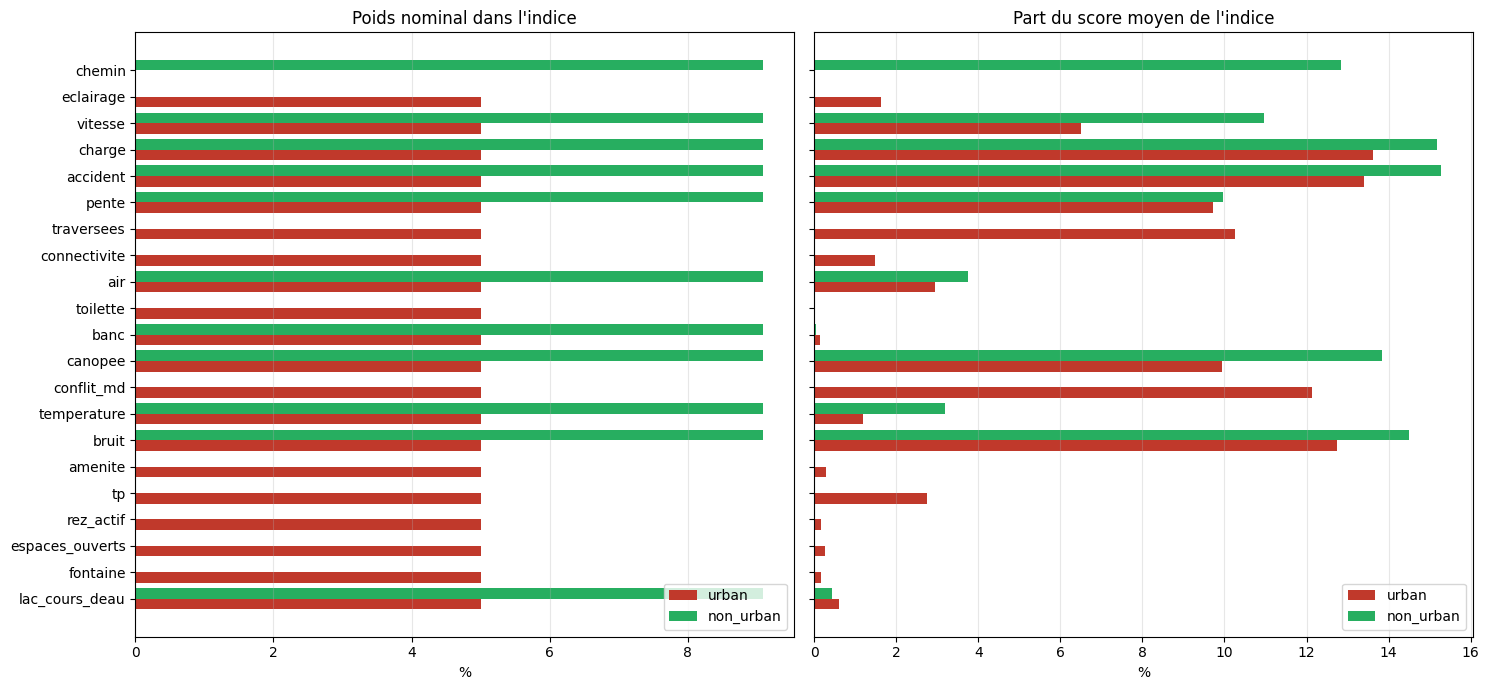

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
order_idx = m2_index.index
grouped_barh(pd.DataFrame({k: m2_index[(k, "poids_nominal_%")] for k in data}), "Poids nominal dans l'indice", "%", ax=axes[0], order=order_idx)
grouped_barh(pd.DataFrame({k: m2_index[(k, "part_%")] for k in data}), "Part du score moyen de l'indice", "%", ax=axes[1], order=order_idx)
plt.tight_layout(); plt.savefig(OUT_DIR / "2_contrib_index.png", dpi=150); plt.show()

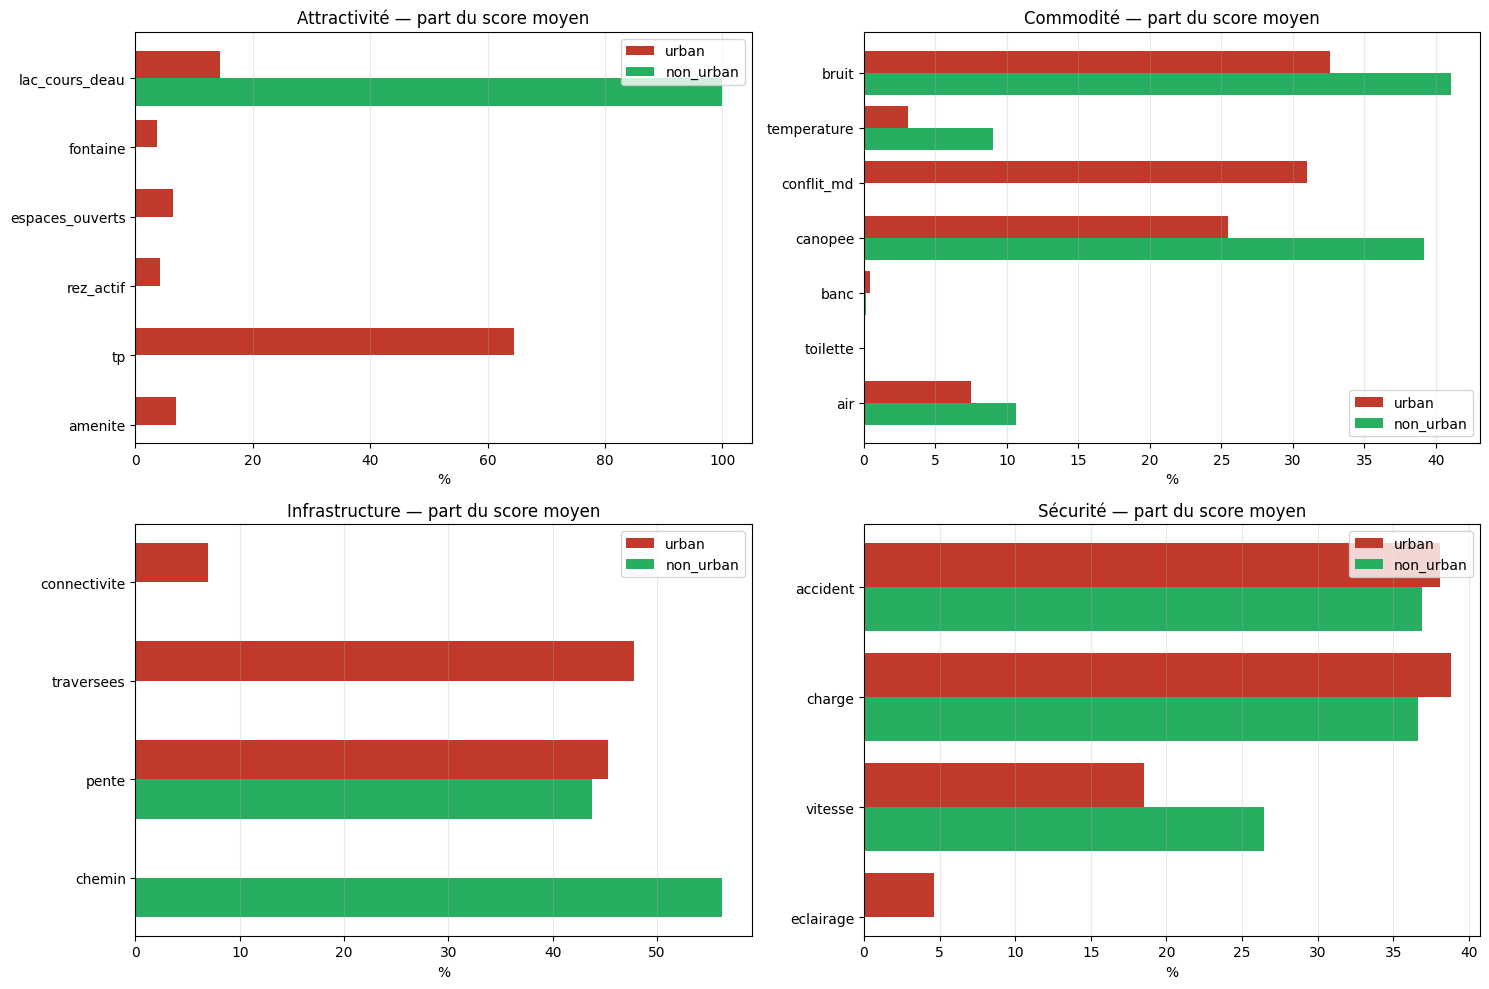


=== Attractivité ===


urban                          non_urban                        
                contrib_moy part_% poids_nominal_% contrib_moy  part_% poids_nominal_%
lac_cours_deau        0.007 14.338          16.667       0.029 100.000         100.000
fontaine              0.002  3.698          16.667         NaN     NaN             NaN
espaces_ouverts       0.003  6.335          16.667         NaN     NaN             NaN
rez_actif             0.002  4.230          16.667         NaN     NaN             NaN
tp                    0.031 64.423          16.667         NaN     NaN             NaN
amenite               0.003  6.976          16.667         NaN     NaN             NaN


=== Commodité ===


urban                          non_urban                       
            contrib_moy part_% poids_nominal_% contrib_moy part_% poids_nominal_%
bruit             0.123 32.575          14.286       0.187 41.029          20.000
temperature       0.012  3.069          14.286       0.041  9.027          20.000
conflit_md        0.117 30.986          14.286         NaN    NaN             NaN
canopee           0.096 25.427          14.286       0.178 39.189          20.000
banc              0.002  0.400          14.286       0.001  0.149          20.000
toilette          0.000  0.030          14.286         NaN    NaN             NaN
air               0.028  7.514          14.286       0.048 10.606          20.000


=== Infrastructure ===


urban                          non_urban                       
             contrib_moy part_% poids_nominal_% contrib_moy part_% poids_nominal_%
connectivite       0.033  6.913          33.333         NaN    NaN             NaN
traversees         0.231 47.817          33.333         NaN    NaN             NaN
pente              0.219 45.270          33.333       0.321 43.733          50.000
chemin               NaN    NaN             NaN       0.413 56.267          50.000


=== Sécurité ===


urban                          non_urban                       
          contrib_moy part_% poids_nominal_% contrib_moy part_% poids_nominal_%
accident        0.226 38.102          25.000       0.328 36.889          33.333
charge          0.230 38.779          25.000       0.326 36.635          33.333
vitesse         0.110 18.492          25.000       0.236 26.476          33.333
eclairage       0.028  4.627          25.000         NaN    NaN             NaN

In [13]:
# --- dans chaque classe
m2_class = {}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, c in zip(axes.flat, CLASSES):
    t = {}
    for k, d in data.items():
        cb = d["contrib"][("class", c)]
        if cb.shape[1]:
            tt = mean_contrib(cb); tt["poids_nominal_%"] = nominal_share(d, "class", c); t[k] = tt
    m2_class[c] = pd.concat(t, axis=1)
    grouped_barh(pd.DataFrame({k: m2_class[c][(k, "part_%")] for k in t}), f"{c} — part du score moyen", "%", ax=ax)
plt.tight_layout(); plt.savefig(OUT_DIR / "2_contrib_classes.png", dpi=150); plt.show()
for c in CLASSES:
    print(f"\n=== {c} ==="); display(m2_class[c])

## 3. Décomposition de variance

Pour une cible $Y$ (score de classe ou walk index **tels que dans le gpkg**) :

$$\mathrm{Var}(Y) = \sum_a \mathrm{Cov}(c_a, Y) + \mathrm{Cov}(\varepsilon, Y), \qquad \varepsilon = Y - \sum_a c_a$$

La part $\mathrm{Cov}(c_a, Y)/\mathrm{Var}(Y)$ dit **quel attribut explique les différences entre carreaux**. Les parts somment exactement à 100 % (résidu inclus). Une part peut être négative si l'attribut varie à contre-sens du reste de l'indice.

On ajoute les **poids effectifs** : coefficients d'une régression linéaire de $Y$ sur les attributs, ramenés en %. S'ils s'écartent des poids nominaux, la formule réelle du step3 diffère du modèle simple.

In [14]:
def variance_decomp(contrib_df, y):
    var = y.var()
    shares = contrib_df.apply(lambda c: np.cov(c, y)[0, 1]) / var * 100
    resid = y - contrib_df.sum(axis=1)
    shares["(résidu)"] = np.cov(resid, y)[0, 1] / var * 100
    return shares

def effective_weights(X, y):
    A = np.c_[X.values, np.ones(len(X))]
    b, *_ = np.linalg.lstsq(A, y.values, rcond=None)
    coef = pd.Series(b[:-1], index=X.columns)
    return coef / coef.sum() * 100

m3 = {}
for k, d in data.items():
    y = d["df"][d["index_col"]]
    cb = d["contrib"][("index", None)]
    m3[k] = pd.DataFrame({
        "part_variance_%": variance_decomp(cb, y),
        "poids_nominal_%": nominal_share(d, "index"),
        "poids_effectif_OLS_%": effective_weights(d["df"][cb.columns], y),
    })
m3_index = pd.concat(m3, axis=1)
m3_index

urban                                            non_urban                                     
                part_variance_% poids_nominal_% poids_effectif_OLS_% part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)                 24.056             NaN                  NaN          23.355             NaN                  NaN
accident                  5.474           5.000                5.007           2.880           9.091                7.459
air                       0.789           5.000                5.508           2.263           9.091               10.342
amenite                   0.907           5.000                4.974             NaN             NaN                  NaN
banc                      0.976           5.000                4.748          -0.009           9.091               10.271
bruit                     7.173           5.000                5.062           7.274           9.091               11.324
canopee                   8.650           5.000                4.925           5.500           9.091                5.746
charge                    4.834           5.000                5.022           4.079           9.091                9.042
conflit_md                4.454           5.000                5.052             NaN             NaN                  NaN
connectivite             -0.336           5.000                5.198             NaN             NaN                  NaN
eclairage                 2.376           5.000                5.061             NaN             NaN                  NaN
espaces_ouverts           1.699           5.000                5.239             NaN             NaN                  NaN
fontaine                  0.771           5.000                5.059             NaN             NaN                  NaN
lac_cours_deau            3.532           5.000                4.809           1.206           9.091                9.763
pente                     0.489           5.000                4.929          -0.978           9.091                9.067
rez_actif                 0.844           5.000                5.032             NaN             NaN                  NaN
temperature               2.956           5.000                5.089           6.301           9.091                7.311
toilette                  0.077           5.000                4.540             NaN             NaN                  NaN
tp                        2.991           5.000                5.110             NaN             NaN                  NaN
traversees               11.789           5.000                4.782             NaN             NaN                  NaN
vitesse                  15.497           5.000                4.852          23.350           9.091               10.779
chemin                      NaN             NaN                  NaN          24.779           9.091                8.896

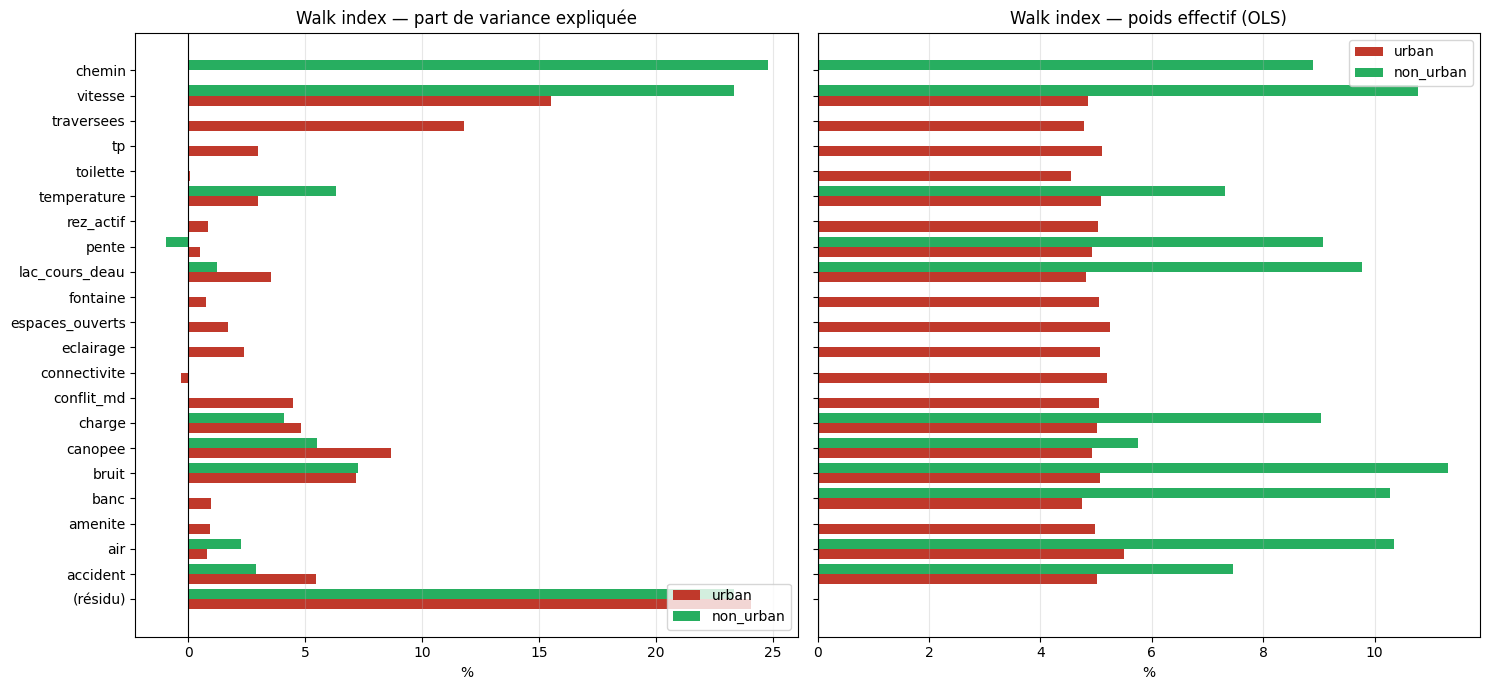

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
order3 = m3_index.index
grouped_barh(pd.DataFrame({k: m3_index[(k, "part_variance_%")] for k in data}), "Walk index — part de variance expliquée", "%", ax=axes[0], order=order3)
grouped_barh(pd.DataFrame({k: m3_index[(k, "poids_effectif_OLS_%")] for k in data}), "Walk index — poids effectif (OLS)", "%", ax=axes[1], order=order3)
for ax in axes: ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.savefig(OUT_DIR / "3_variance_index.png", dpi=150); plt.show()

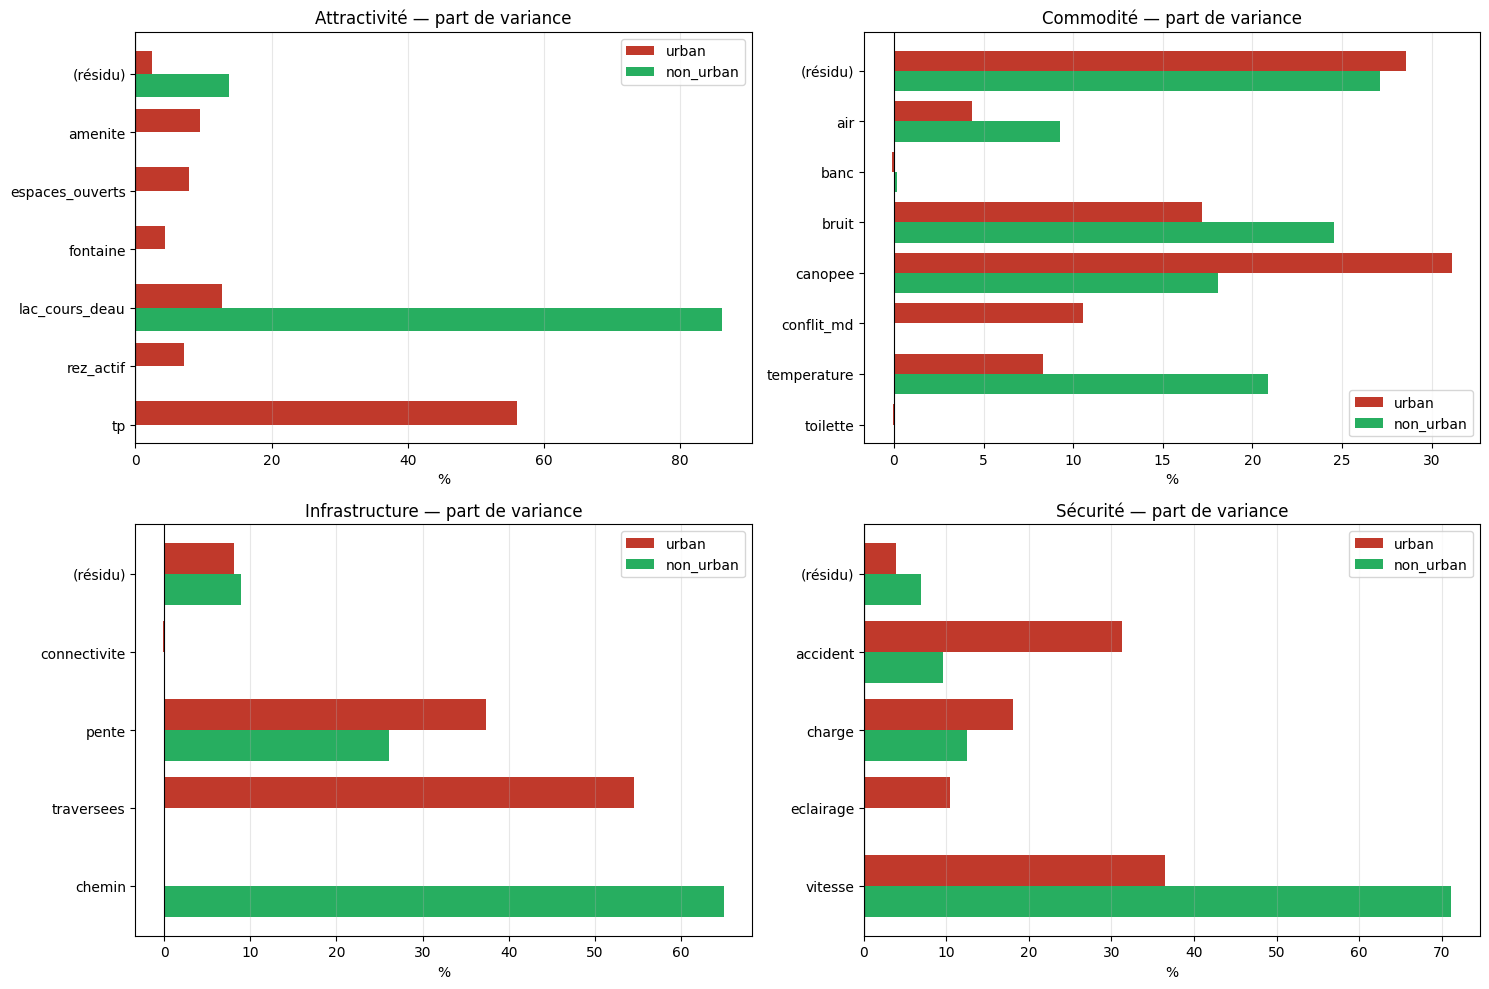


=== Attractivité ===


urban                                            non_urban                                     
                part_variance_% poids_nominal_% poids_effectif_OLS_% part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)                  2.438             NaN                  NaN          13.759             NaN                  NaN
amenite                   9.445          16.667               16.589             NaN             NaN                  NaN
espaces_ouverts           7.854          16.667               16.519             NaN             NaN                  NaN
fontaine                  4.378          16.667               16.719             NaN             NaN                  NaN
lac_cours_deau           12.711          16.667               16.295          86.241         100.000              100.000
rez_actif                 7.163          16.667               16.861             NaN             NaN                  NaN
tp                       56.010          16.667               17.017             NaN             NaN                  NaN


=== Commodité ===


urban                                            non_urban                                     
            part_variance_% poids_nominal_% poids_effectif_OLS_% part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)             28.596             NaN                  NaN          27.116             NaN                  NaN
air                   4.384          14.286               14.560           9.242          20.000               20.769
banc                 -0.114          14.286               13.832           0.160          20.000               20.538
bruit                17.174          14.286               14.389          24.535          20.000               21.029
canopee              31.138          14.286               14.117          18.084          20.000               18.383
conflit_md           10.569          14.286               14.109             NaN             NaN                  NaN
temperature           8.297          14.286               14.417          20.862          20.000               19.281
toilette             -0.043          14.286               14.575             NaN             NaN                  NaN


=== Infrastructure ===


urban                                            non_urban                                     
             part_variance_% poids_nominal_% poids_effectif_OLS_% part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)               8.151             NaN                  NaN           8.910             NaN                  NaN
connectivite          -0.076          33.333               34.304             NaN             NaN                  NaN
pente                 37.337          33.333               33.122          26.128          50.000               51.934
traversees            54.588          33.333               32.575             NaN             NaN                  NaN
chemin                   NaN             NaN                  NaN          64.962          50.000               48.066


=== Sécurité ===


urban                                            non_urban                                     
          part_variance_% poids_nominal_% poids_effectif_OLS_% part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)            3.893             NaN                  NaN           6.876             NaN                  NaN
accident           31.250          25.000               25.017           9.575          33.333               30.018
charge             18.020          25.000               25.280          12.461          33.333               33.993
eclairage          10.412          25.000               25.403             NaN             NaN                  NaN
vitesse            36.425          25.000               24.300          71.087          33.333               35.989

In [16]:
# Variance par classe : attributs -> classe, et classes -> indice
m3_class = {}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, c in zip(axes.flat, CLASSES):
    t = {}
    for k, d in data.items():
        cb = d["contrib"][("class", c)]
        if cb.shape[1]:
            y = d["df"][d["class_cols"][c]]
            t[k] = pd.DataFrame({"part_variance_%": variance_decomp(cb, y),
                                 "poids_nominal_%": nominal_share(d, "class", c),
                                 "poids_effectif_OLS_%": effective_weights(d["df"][cb.columns], y)})
    m3_class[c] = pd.concat(t, axis=1)
    grouped_barh(pd.DataFrame({k: m3_class[c][(k, "part_variance_%")] for k in t}), f"{c} — part de variance", "%", ax=ax)
    ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.savefig(OUT_DIR / "3_variance_classes.png", dpi=150); plt.show()
for c in CLASSES:
    print(f"\n=== {c} ==="); display(m3_class[c])

### 3 bis. Covariances des attributs au sein de chaque classe

Pour chaque classe et chaque layer :
- **matrice de covariance brute** $\mathrm{Cov}(x_a, x_b)$ des attributs de la classe ;
- **matrice de contribution à la variance** $M_{ab} = \tilde w_a \tilde w_b\,\mathrm{Cov}(x_a, x_b) / \mathrm{Var}(Y)$ en %, avec $Y$ le score de classe du gpkg. La **diagonale** est l'effet propre de chaque attribut, les **hors-diagonales** sont les effets de covariance (rouge = renforcement, bleu = compensation). La somme d'une ligne + le résidu = part de variance de l'attribut (métrique 3) ;
- tableau **effet propre / covariance avec les autres / résidu / total**.

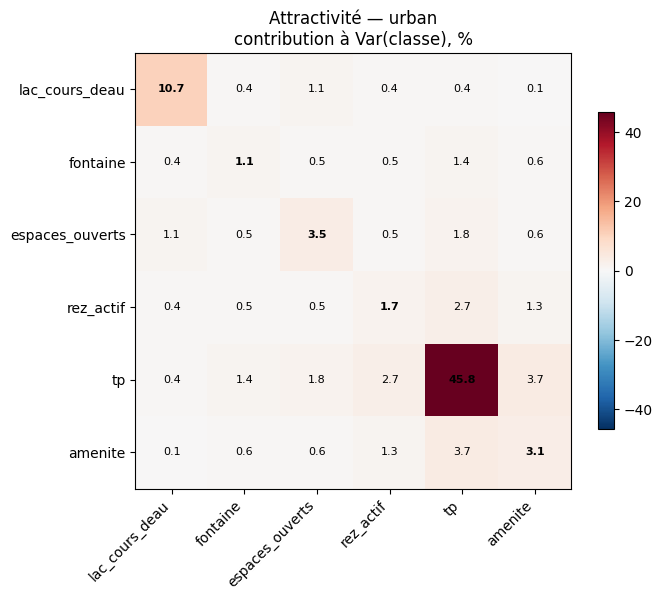


=== Attractivité — urban : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
lac_cours_deau,10.681,2.395,-0.365,12.711
fontaine,1.083,3.318,-0.023,4.378
espaces_ouverts,3.470,4.478,-0.093,7.854
rez_actif,1.746,5.433,-0.016,7.163
tp,45.762,9.868,0.380,56.010
amenite,3.137,6.334,-0.026,9.445


--- Attractivité — urban : covariance brute ---


,lac_cours_deau,fontaine,espaces_ouverts,rez_actif,tp,amenite
lac_cours_deau,0.0253,0.0010,0.0025,0.0010,0.0009,0.0003
fontaine,0.0010,0.0026,0.0011,0.0011,0.0033,0.0013
espaces_ouverts,0.0025,0.0011,0.0082,0.0013,0.0042,0.0015
rez_actif,0.0010,0.0011,0.0013,0.0041,0.0063,0.0032
tp,0.0009,0.0033,0.0042,0.0063,0.1082,0.0087
amenite,0.0003,0.0013,0.0015,0.0032,0.0087,0.0074


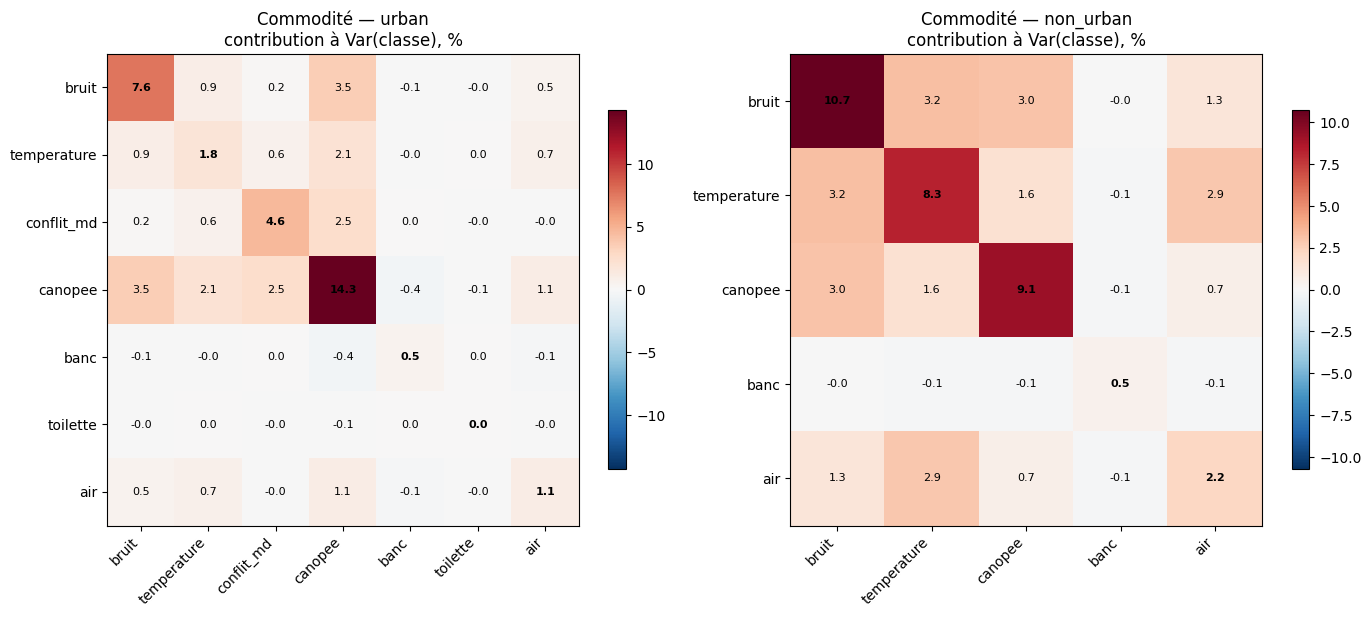


=== Commodité — urban : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
bruit,7.594,4.935,4.644,17.174
temperature,1.819,4.242,2.236,8.297
conflit_md,4.630,3.181,2.757,10.569
canopee,14.269,8.626,8.242,31.138
banc,0.545,-0.612,-0.046,-0.114
toilette,0.027,-0.059,-0.011,-0.043
air,1.080,2.104,1.200,4.384


--- Commodité — urban : covariance brute ---


,bruit,temperature,conflit_md,canopee,banc,toilette,air
bruit,0.0351,0.0043,0.0007,0.0160,-0.0003,-0.0000,0.0021
temperature,0.0043,0.0084,0.0026,0.0095,-0.0002,0.0000,0.0033
conflit_md,0.0007,0.0026,0.0214,0.0115,0.0001,-0.0000,-0.0002
canopee,0.0160,0.0095,0.0115,0.0659,-0.0019,-0.0003,0.0050
banc,-0.0003,-0.0002,0.0001,-0.0019,0.0025,0.0001,-0.0006
toilette,-0.0000,0.0000,-0.0000,-0.0003,0.0001,0.0001,-0.0000
air,0.0021,0.0033,-0.0002,0.0050,-0.0006,-0.0000,0.0050



=== Commodité — non_urban : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
bruit,10.714,7.527,6.294,24.535
temperature,8.256,7.610,4.997,20.862
canopee,9.131,5.111,3.843,18.084
banc,0.495,-0.400,0.065,0.160
air,2.198,4.773,2.271,9.242


--- Commodité — non_urban : covariance brute ---


,bruit,temperature,canopee,banc,air
bruit,0.0250,0.0075,0.0070,-0.0000,0.0030
temperature,0.0075,0.0193,0.0037,-0.0003,0.0068
canopee,0.0070,0.0037,0.0213,-0.0003,0.0015
banc,-0.0000,-0.0003,-0.0003,0.0012,-0.0002
air,0.0030,0.0068,0.0015,-0.0002,0.0051


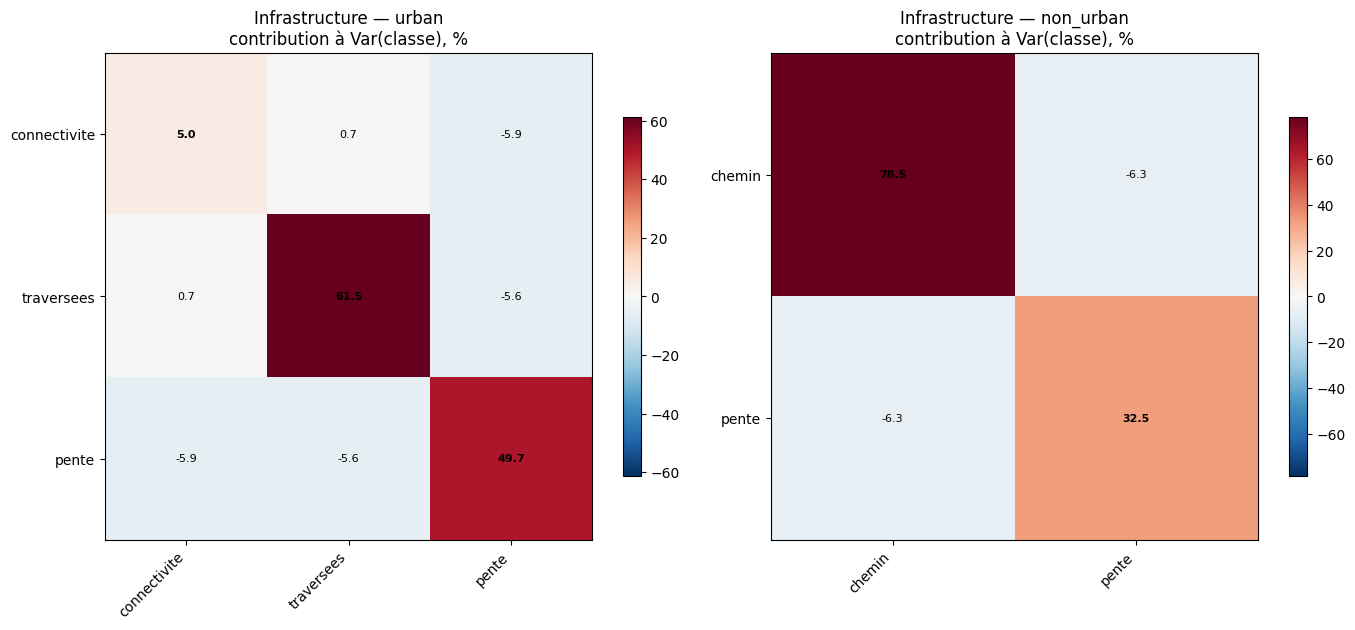


=== Infrastructure — urban : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
connectivite,5.024,-5.269,0.170,-0.076
traversees,61.494,-4.928,-1.978,54.588
pente,49.678,-11.547,-0.794,37.337


--- Infrastructure — urban : covariance brute ---


,connectivite,traversees,pente
connectivite,0.0035,0.0005,-0.0041
traversees,0.0005,0.0424,-0.0039
pente,-0.0041,-0.0039,0.0342



=== Infrastructure — non_urban : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
chemin,78.496,-6.298,-7.236,64.962
pente,32.516,-6.298,-0.090,26.128


--- Infrastructure — non_urban : covariance brute ---


,chemin,pente
chemin,0.1061,-0.0085
pente,-0.0085,0.0440


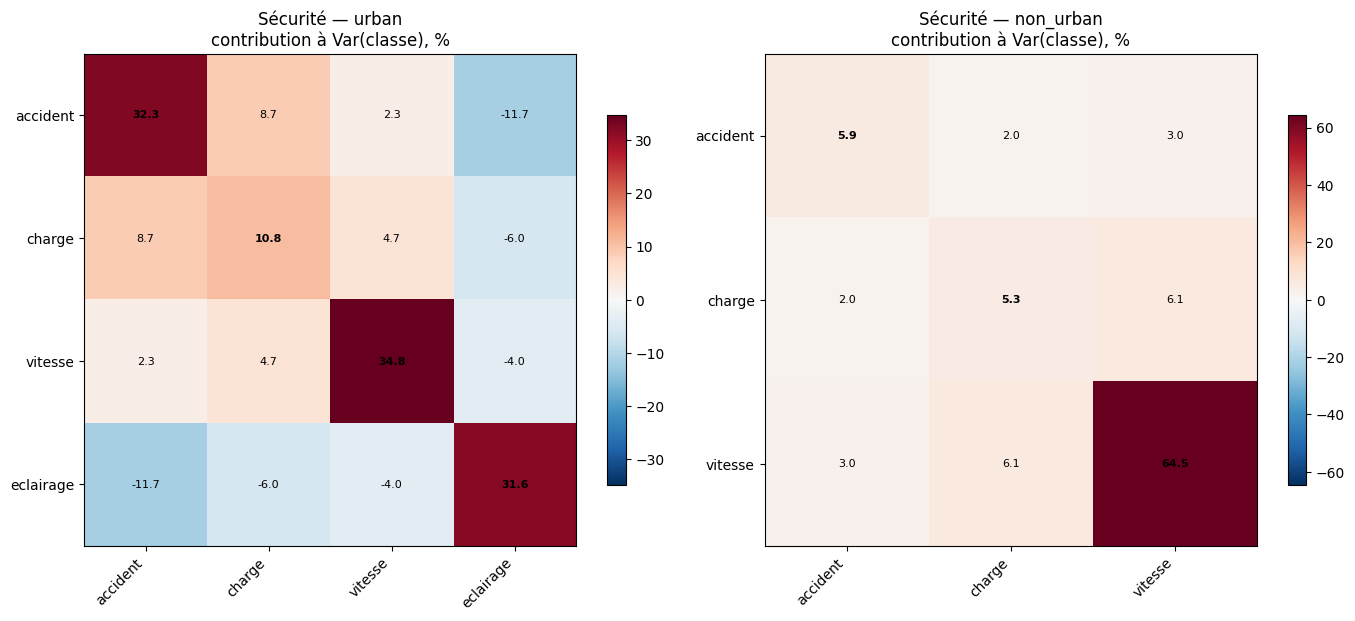


=== Sécurité — urban : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
accident,32.335,-0.672,-0.413,31.250
charge,10.828,7.455,-0.263,18.020
vitesse,34.785,2.953,-1.313,36.425
eclairage,31.567,-21.606,0.451,10.412


--- Sécurité — urban : covariance brute ---


,accident,charge,vitesse,eclairage
accident,0.0570,0.0154,0.0040,-0.0206
charge,0.0154,0.0191,0.0082,-0.0105
vitesse,0.0040,0.0082,0.0613,-0.0070
eclairage,-0.0206,-0.0105,-0.0070,0.0556



=== Sécurité — non_urban : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
accident,5.857,5.026,-1.307,9.575
charge,5.259,8.121,-0.919,12.461
vitesse,64.506,9.062,-2.480,71.087


--- Sécurité — non_urban : covariance brute ---


,accident,charge,vitesse
accident,0.0079,0.0028,0.0040
charge,0.0028,0.0071,0.0082
vitesse,0.0040,0.0082,0.0873


In [17]:
def class_cov_decomp(d, cls):
    w = d["weights"]
    s = w[(w["Class"] == cls) & (w["class_weight"] > 0)]["class_weight"]
    if not len(s):
        return None
    wn = s / s.sum()
    X = d["df"][s.index]
    y = d["df"][d["class_cols"][cls]]
    var_y = y.var()
    cov = X.cov()
    M = cov * np.outer(wn, wn) / var_y * 100
    resid = y - (X * wn.values).sum(axis=1)
    res = pd.Series({a: wn[a] * np.cov(X[a], resid)[0, 1] / var_y * 100 for a in s.index})
    table = pd.DataFrame({
        "effet_propre_%": np.diag(M),
        "covariance_autres_%": M.sum(axis=1) - np.diag(M),
        "residu_%": res,
    }, index=s.index)
    table["total_%"] = table.sum(axis=1)
    return {"cov": cov, "corr": X.corr(), "M": M, "table": table}


def plot_matrix(ax, M, title, fmt="{:.1f}"):
    lim = np.nanmax(np.abs(M.values)) or 1
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(M)), M.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(M)), M.index)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M.iat[i, j]), ha="center", va="center", fontsize=8,
                    fontweight="bold" if i == j else "normal")
    ax.set_title(title)
    return im


cov_results = {}
for c in CLASSES:
    res = {k: class_cov_decomp(d, c) for k, d in data.items()}
    res = {k: v for k, v in res.items() if v is not None and len(v["M"]) > 1}
    cov_results[c] = res
    if not res:
        print(f"{c} : un seul attribut dans chaque layer, pas de covariance à afficher.")
        continue
    fig, axes = plt.subplots(1, len(res), figsize=(7 * len(res), 6), squeeze=False)
    for ax, (k, r) in zip(axes[0], res.items()):
        im = plot_matrix(ax, r["M"], f"{c} — {k}\ncontribution à Var(classe), %")
        fig.colorbar(im, ax=ax, shrink=.7)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"3bis_covariance_{c}.png", dpi=150); plt.show()
    for k, r in res.items():
        print(f"\n=== {c} — {k} : décomposition ===")
        display(r["table"])
        print(f"--- {c} — {k} : covariance brute ---")
        display(r["cov"].style.format("{:.4f}").background_gradient(cmap="RdBu_r", axis=None))

In [18]:
# Niveau classes -> walk index (avec les vrais scores de classe du gpkg)
rows = {}
for k, d in data.items():
    y = d["df"][d["index_col"]]
    Cdf = pd.DataFrame({c: d["df"][d["class_cols"][c]] * cls_w.loc[c, k] for c in CLASSES})
    rows[k] = pd.DataFrame({"poids_nominal_%": cls_w[k] * 100,
                            "part_variance_%": variance_decomp(Cdf, y),
                            "poids_effectif_OLS_%": effective_weights(d["df"][list(d["class_cols"].values())].set_axis(CLASSES, axis=1), y)})
m3_classes_to_index = pd.concat(rows, axis=1)
m3_classes_to_index

urban                                            non_urban                                     
               poids_nominal_% part_variance_% poids_effectif_OLS_% poids_nominal_% part_variance_% poids_effectif_OLS_%
(résidu)                   NaN          10.810                  NaN             NaN          12.254                  NaN
Attractivité            30.000          11.549               33.181           9.091           1.467               10.377
Commodité               35.000          35.390               28.320          45.455          29.387               37.729
Infrastructure          15.000          12.945               16.393          18.182          24.793               20.631
Sécurité                20.000          29.306               22.106          27.273          32.099               31.263

## 4. Déficit (manque à gagner)

$d_a = \tilde w_a\,(1 - x_a)$ : ce que l'attribut fait perdre par rapport à un carreau parfait. La somme des $d_a$ vaut $1-\hat I$.

Calculé sur **tous les carreaux** et sur le **quartile inférieur** de l'indice de la layer (les carreaux les moins bien notés), pour voir ce qui tire spécifiquement vers le bas.

In [19]:
def deficit_table(d, level="index", cls=None):
    w = d["weights"]; df = d["df"]
    if level == "index":
        s = w[w["initial_weight"] > 0]["initial_weight"]; y = df[d["index_col"]]
    else:
        s = w[(w["Class"] == cls) & (w["class_weight"] > 0)]["class_weight"]; y = df[d["class_cols"][cls]]
    if not len(s):
        return None
    D = (1 - df[s.index]) * (s / s.sum()).values
    q1 = y <= y.quantile(.25)
    return pd.DataFrame({
        "deficit_moy": D.mean(), "part_deficit_%": D.mean() / D.mean().sum() * 100,
        "deficit_moy_Q1": D[q1].mean(), "part_deficit_Q1_%": D[q1].mean() / D[q1].mean().sum() * 100,
    })

m4_index = pd.concat({k: deficit_table(d) for k, d in data.items()}, axis=1)
m4_index

urban                                                   non_urban                                                
                deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_% deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
lac_cours_deau        0.048          7.243          0.049             6.906       0.088         21.318          0.089            17.090
fontaine              0.049          7.475          0.050             7.007         NaN            NaN            NaN               NaN
espaces_ouverts       0.049          7.417          0.050             6.983         NaN            NaN            NaN               NaN
rez_actif             0.049          7.463          0.050             6.984         NaN            NaN            NaN               NaN
tp                    0.041          6.148          0.043             6.036         NaN            NaN            NaN               NaN
amenite               0.049          7.403          0.049             6.952         NaN            NaN            NaN               NaN
bruit                 0.007          1.042          0.013             1.809       0.006          1.459          0.015             2.967
temperature           0.046          6.942          0.048             6.707       0.072         17.439          0.080            15.467
conflit_md            0.009          1.359          0.012             1.669         NaN            NaN            NaN               NaN
canopee               0.016          2.471          0.023             3.231       0.010          2.377          0.017             3.340
banc                  0.049          7.476          0.050             7.006       0.091         21.873          0.091            17.476
toilette              0.050          7.550          0.050             7.035         NaN            NaN            NaN               NaN
air                   0.040          6.053          0.041             5.726       0.069         16.651          0.072            13.860
connectivite          0.045          6.797          0.045             6.285         NaN            NaN            NaN               NaN
traversees            0.015          2.310          0.022             3.151         NaN            NaN            NaN               NaN
pente                 0.017          2.590          0.018             2.502       0.032          7.844          0.029             5.669
accident              0.005          0.711          0.009             1.319       0.001          0.329          0.005             0.872
charge                0.004          0.590          0.008             1.093       0.002          0.478          0.007             1.273
vitesse               0.028          4.234          0.037             5.178       0.027          6.432          0.062            11.917
eclairage             0.044          6.725          0.046             6.422         NaN            NaN            NaN               NaN
chemin                  NaN            NaN            NaN               NaN       0.016          3.802          0.052            10.070

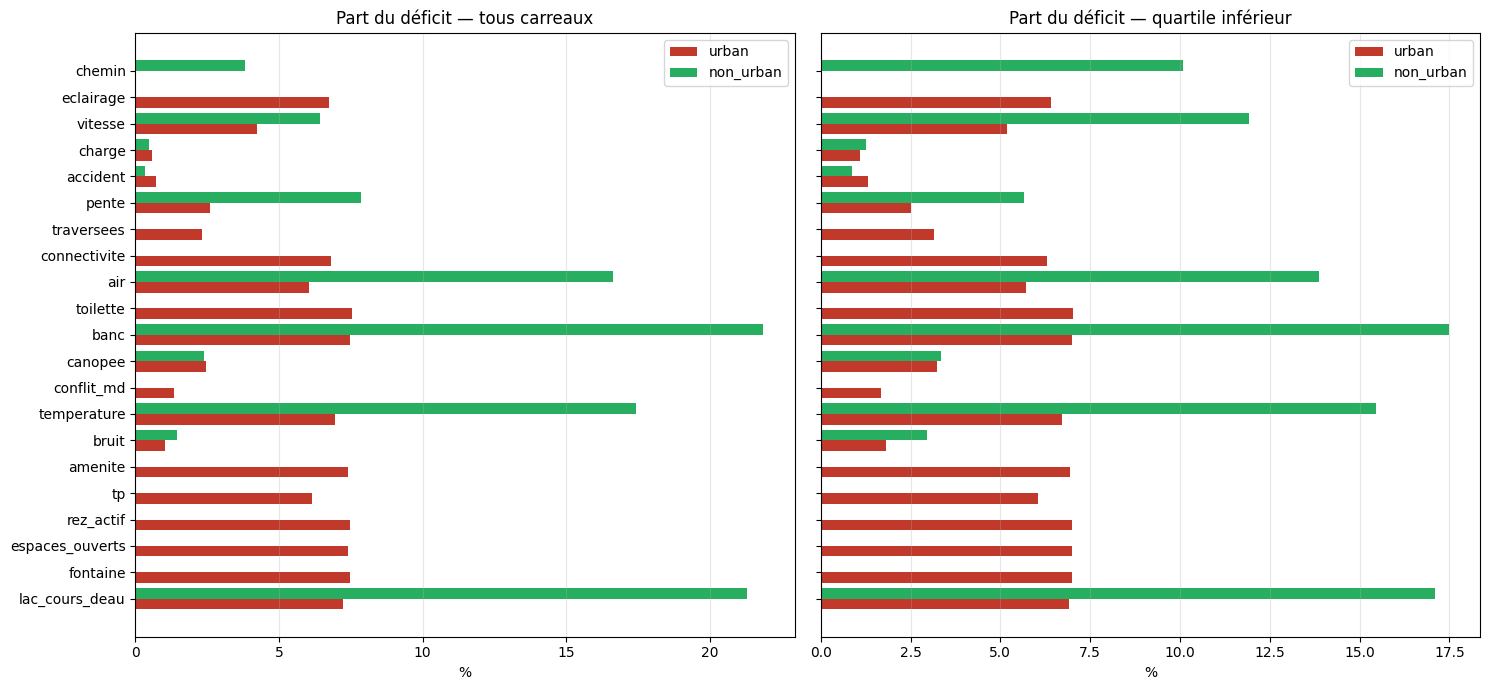

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
order4 = m4_index.index
grouped_barh(pd.DataFrame({k: m4_index[(k, "part_deficit_%")] for k in data}), "Part du déficit — tous carreaux", "%", ax=axes[0], order=order4)
grouped_barh(pd.DataFrame({k: m4_index[(k, "part_deficit_Q1_%")] for k in data}), "Part du déficit — quartile inférieur", "%", ax=axes[1], order=order4)
plt.tight_layout(); plt.savefig(OUT_DIR / "4_deficit_index.png", dpi=150); plt.show()

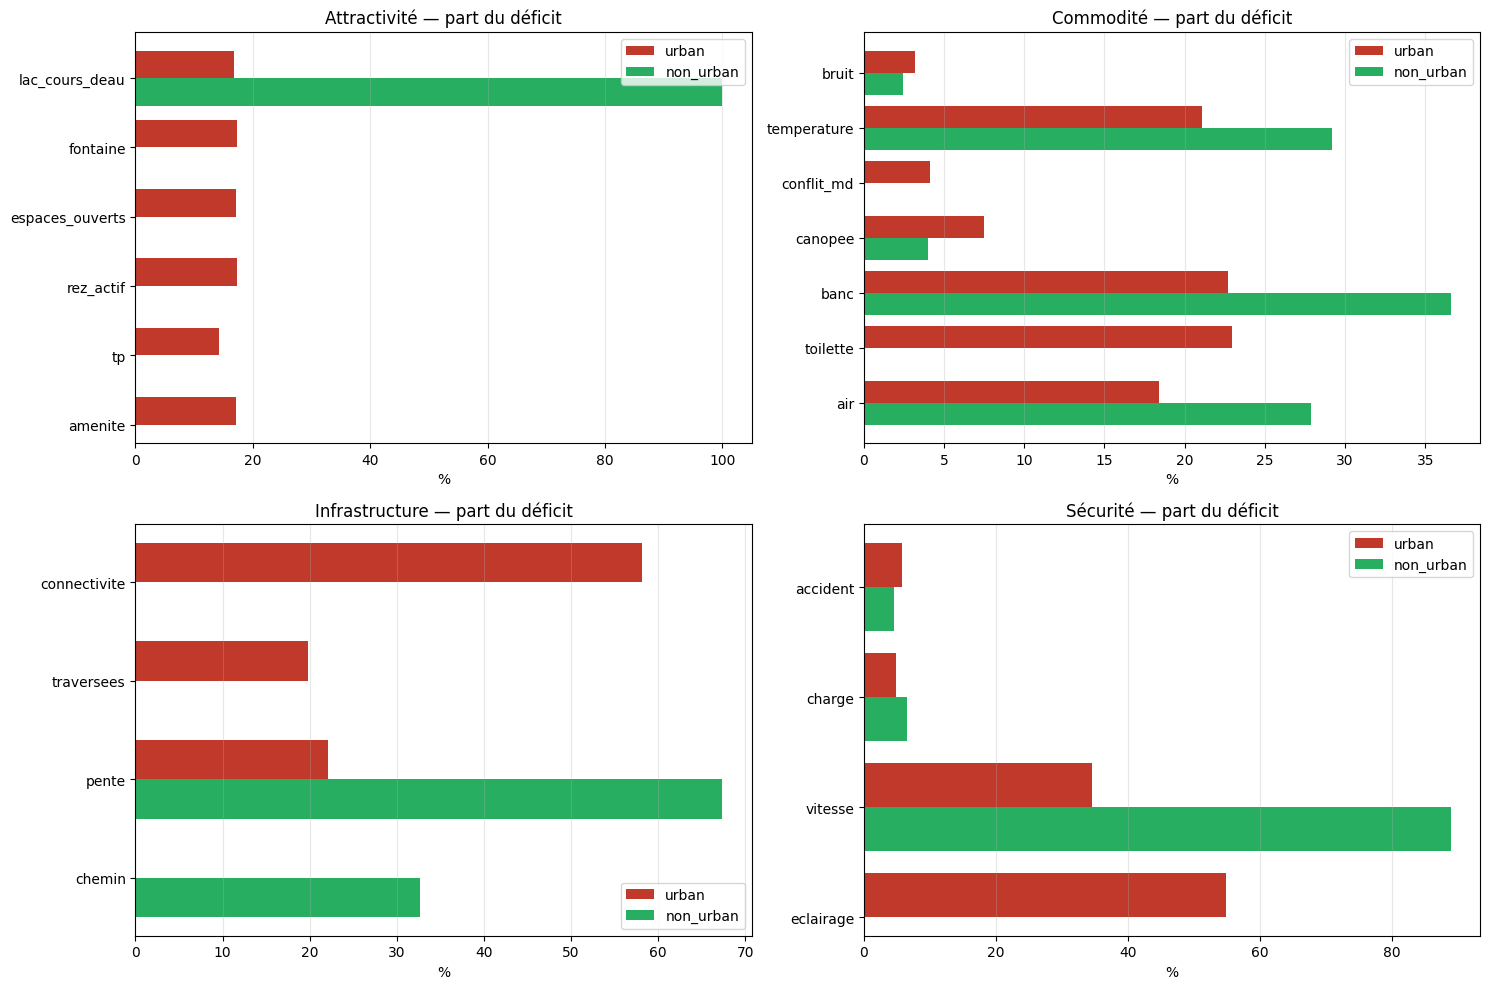


=== Attractivité ===


urban                                                   non_urban                                                
                deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_% deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
lac_cours_deau        0.160         16.785          0.166            16.619       0.971        100.000          0.998           100.000
fontaine              0.165         17.323          0.167            16.677         NaN            NaN            NaN               NaN
espaces_ouverts       0.164         17.190          0.167            16.673         NaN            NaN            NaN               NaN
rez_actif             0.165         17.296          0.167            16.680         NaN            NaN            NaN               NaN
tp                    0.136         14.249          0.167            16.669         NaN            NaN            NaN               NaN
amenite               0.163         17.157          0.167            16.681         NaN            NaN            NaN               NaN


=== Commodité ===


urban                                                   non_urban                                                
            deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_% deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
bruit             0.020          3.167          0.044             6.076       0.013          2.439          0.047             7.302
temperature       0.131         21.105          0.140            19.506       0.159         29.163          0.185            28.832
conflit_md        0.026          4.133          0.039             5.381         NaN            NaN            NaN               NaN
canopee           0.047          7.512          0.092            12.850       0.022          3.975          0.046             7.112
banc              0.141         22.728          0.141            19.663       0.199         36.577          0.199            31.055
toilette          0.143         22.953          0.143            19.901         NaN            NaN            NaN               NaN
air               0.114         18.403          0.119            16.623       0.152         27.845          0.165            25.699


=== Infrastructure ===


urban                                                   non_urban                                                
             deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_% deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
connectivite       0.300         58.111          0.303            48.675         NaN            NaN            NaN               NaN
traversees         0.102         19.750          0.164            26.455         NaN            NaN            NaN               NaN
pente              0.114         22.139          0.155            24.870       0.179         67.356          0.242            47.250
chemin               NaN            NaN            NaN               NaN       0.087         32.644          0.270            52.750


=== Sécurité ===


urban                                                   non_urban                                                
          deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_% deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
accident        0.024          5.802          0.072            13.463       0.005          4.543          0.017             6.166
charge          0.020          4.810          0.047             8.839       0.007          6.607          0.024             8.703
vitesse         0.140         34.537          0.192            35.868       0.098         88.850          0.239            85.131
eclairage       0.222         54.852          0.224            41.830         NaN            NaN            NaN               NaN

In [21]:
m4_class = {}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, c in zip(axes.flat, CLASSES):
    t = {k: deficit_table(d, "class", c) for k, d in data.items()}
    t = {k: v for k, v in t.items() if v is not None}
    m4_class[c] = pd.concat(t, axis=1)
    grouped_barh(pd.DataFrame({k: m4_class[c][(k, "part_deficit_%")] for k in t}), f"{c} — part du déficit", "%", ax=ax)
plt.tight_layout(); plt.savefig(OUT_DIR / "4_deficit_classes.png", dpi=150); plt.show()
for c in CLASSES:
    print(f"\n=== {c} ==="); display(m4_class[c])

## 5. Corrélations de Spearman

Corrélation de rang entre chaque attribut et chaque score (classes + indice) de la même layer. Robuste aux distributions très asymétriques. Les attributs à poids 0 sont inclus pour voir s'ils sont redondants avec ceux qui pèsent.

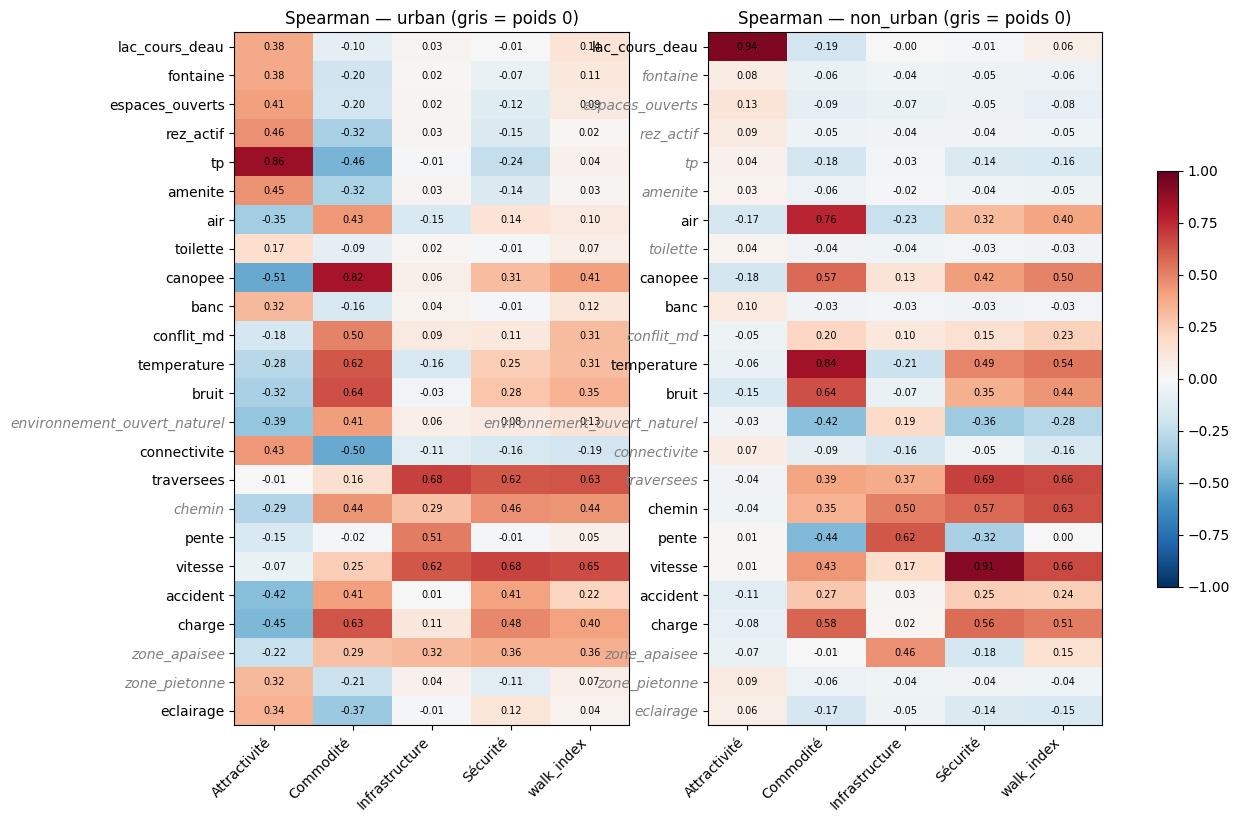

urban                                                 non_urban                                             
                             Attractivité Commodité Infrastructure Sécurité walk_index Attractivité Commodité Infrastructure Sécurité walk_index
attribute                                                                                                                                       
lac_cours_deau                      0.379    -0.096          0.029   -0.007      0.138        0.937    -0.193         -0.004   -0.012      0.062
fontaine                            0.380    -0.196          0.020   -0.066      0.106        0.077    -0.063         -0.043   -0.054     -0.061
espaces_ouverts                     0.409    -0.195          0.025   -0.118      0.087        0.129    -0.095         -0.069   -0.049     -0.082
rez_actif                           0.456    -0.323          0.031   -0.146      0.019        0.086    -0.053         -0.037   -0.036     -0.045
tp                                  0.855    -0.463         -0.012   -0.239      0.044        0.042    -0.181         -0.031   -0.145     -0.156
amenite                             0.448    -0.320          0.030   -0.143      0.025        0.033    -0.059         -0.016   -0.044     -0.052
air                                -0.350     0.431         -0.151    0.140      0.101       -0.170     0.759         -0.227    0.316      0.396
toilette                            0.168    -0.093          0.019   -0.008      0.067        0.038    -0.036         -0.039   -0.026     -0.035
canopee                            -0.506     0.823          0.058    0.308      0.412       -0.182     0.570          0.129    0.415      0.500
banc                                0.321    -0.157          0.038   -0.013      0.123        0.101    -0.033         -0.030   -0.034     -0.027
conflit_md                         -0.176     0.496          0.089    0.108      0.314       -0.052     0.204          0.104    0.153      0.231
temperature                        -0.279     0.620         -0.163    0.247      0.309       -0.063     0.841         -0.213    0.488      0.536
bruit                              -0.321     0.642         -0.030    0.275      0.351       -0.152     0.645         -0.066    0.354      0.439
environnement_ouvert_naturel       -0.386     0.415          0.064    0.079      0.125       -0.032    -0.421          0.191   -0.359     -0.282
connectivite                        0.430    -0.502         -0.106   -0.163     -0.192        0.071    -0.090         -0.165   -0.045     -0.155
traversees                         -0.005     0.157          0.680    0.621      0.627       -0.036     0.392          0.374    0.686      0.660
chemin                             -0.292     0.438          0.293    0.460      0.442       -0.040     0.345          0.505    0.570      0.634
pente                              -0.153    -0.019          0.510   -0.014      0.051        0.012    -0.442          0.619   -0.324      0.002
vitesse                            -0.069     0.245          0.620    0.675      0.651        0.012     0.430          0.173    0.907      0.656
accident                           -0.425     0.407          0.007    0.406      0.219       -0.105     0.270          0.030    0.247      0.239
charge                             -0.450     0.626          0.111    0.477      0.399       -0.083     0.583          0.022    0.555      0.509
zone_apaisee                       -0.221     0.290          0.323    0.361      0.364       -0.070    -0.007          0.458   -0.176      0.151
zone_pietonne                       0.323    -0.212          0.044   -0.108      0.066        0.090    -0.056         -0.042   -0.038     -0.042
eclairage                           0.345    -0.369         -0.014    0.121      0.036        0.065    -0.166         -0.051   -0.143     -0.155

In [22]:
def spearman_matrix(d):
    df = d["df"]; targets = {**{c: d["class_cols"][c] for c in CLASSES}, "walk_index": d["index_col"]}
    attrs = d["weights"].sort_values("Class").index
    M = pd.DataFrame({t: [stats.spearmanr(df[a], df[col]).statistic for a in attrs] for t, col in targets.items()}, index=attrs)
    return M

m5 = {k: spearman_matrix(d) for k, d in data.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
for ax, (k, M) in zip(axes, m5.items()):
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(M.shape[1]), M.columns, rotation=45, ha="right"); ax.set_yticks(range(M.shape[0]), M.index)
    w = data[k]["weights"]
    for lbl in ax.get_yticklabels():
        if w.loc[lbl.get_text(), "initial_weight"] == 0: lbl.set_color("grey"); lbl.set_style("italic")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"Spearman — {k} (gris = poids 0)")
fig.colorbar(im, ax=axes, shrink=.6)
plt.savefig(OUT_DIR / "5_spearman.png", dpi=150, bbox_inches="tight"); plt.show()
pd.concat(m5, axis=1)

## Synthèse et export

Un tableau par layer : pour chaque attribut, ses métriques dans le walk index. Export Excel dans `OUT_DIR` (un onglet par niveau).

In [23]:
synth = {}
for k in data:
    s = pd.concat([
        desc[k][["classe", "%zero", "%one", "P5-P95"]],
        m2_index[k][["poids_nominal_%", "part_%"]].rename(columns={"part_%": "part_score_moy_%"}),
        m3_index[k][["part_variance_%", "poids_effectif_OLS_%"]],
        m4_index[k][["part_deficit_%", "part_deficit_Q1_%"]],
        m5[k][["walk_index"]].rename(columns={"walk_index": "spearman_index"}),
    ], axis=1)
    synth[k] = s.sort_values("classe")
synth_cmp = pd.concat(synth, axis=1)
display(synth_cmp)

with pd.ExcelWriter(OUT_DIR / "analyse_poids_attributs.xlsx") as xw:
    synth_cmp.to_excel(xw, sheet_name="synthese_index")
    fid.to_excel(xw, sheet_name="fidelite_reconstruction")
    m3_classes_to_index.to_excel(xw, sheet_name="classes_vers_index")
    for c in CLASSES:
        pd.concat({"contrib": m2_class[c], "variance": m3_class[c], "deficit": m4_class[c]}, axis=1).to_excel(xw, sheet_name=c[:31])
        for k, r in cov_results.get(c, {}).items():
            sh = f"cov_{c[:10]}_{k}"[:31]
            r["table"].to_excel(xw, sheet_name=sh)
            r["M"].to_excel(xw, sheet_name=sh, startrow=len(r["table"]) + 3)
            r["cov"].to_excel(xw, sheet_name=sh, startrow=2 * len(r["table"]) + 6)
print("Exporté :", OUT_DIR.resolve())

urban                                                                                                                                             \
                                      classe  %zero   %one P5-P95 poids_nominal_% part_score_moy_% part_variance_% poids_effectif_OLS_% part_deficit_% part_deficit_Q1_% spearman_index   
lac_cours_deau                  Attractivité 89.386  0.851  0.341           5.000            0.613           3.532                4.809          7.243             6.906          0.138   
fontaine                        Attractivité 92.135  0.005  0.067           5.000            0.158           0.771                5.059          7.475             7.007          0.106   
espaces_ouverts                 Attractivité 91.837  0.153  0.097           5.000            0.271           1.699                5.239          7.417             6.983          0.087   
rez_actif                       Attractivité 90.200  0.005  0.066           5.000            0.181           0.844                5.032          7.463             6.984          0.019   
tp                              Attractivité 66.660  3.949  0.983           5.000            2.753           2.991                5.110          6.148             6.036          0.044   
amenite                         Attractivité 90.060  0.000  0.147           5.000            0.298           0.907                4.974          7.403             6.952          0.025   
air                                Commodité  0.112  0.000  0.245           5.000            2.939           0.789                5.508          6.053             5.726          0.101   
toilette                           Commodité 98.572  0.005  0.000           5.000            0.012           0.077                4.540          7.550             7.035          0.067   
canopee                            Commodité  0.195  0.460  0.813           5.000            9.948           8.650                4.925          2.471             3.231          0.412   
banc                               Commodité 91.298  0.009  0.069           5.000            0.156           0.976                4.748          7.476             7.006          0.123   
conflit_md                         Commodité  0.014  9.688  0.462           5.000           12.122           4.454                5.052          1.359             1.669          0.314   
temperature                        Commodité 17.395  0.000  0.273           5.000            1.201           2.956                5.089          6.942             6.707          0.309   
bruit                              Commodité  0.005 35.112  0.531           5.000           12.744           7.173                5.062          1.042             1.809          0.351   
environnement_ouvert_naturel       Commodité 15.991  0.084  0.870             NaN              NaN             NaN                  NaN            NaN               NaN          0.125   
connectivite                  Infrastructure  0.265  0.000  0.164           5.000            1.484          -0.336                5.198          6.797             6.285         -0.192   
traversees                    Infrastructure  0.553 12.084  0.700           5.000           10.262          11.789                4.782          2.310             3.151          0.627   
chemin                        Infrastructure 38.051 15.633  1.000             NaN              NaN             NaN                  NaN            NaN               NaN          0.442   
pente                         Infrastructure  0.098  0.014  0.598           5.000            9.715           0.489                4.929          2.590             2.502          0.051   
vitesse                             Sécurité  4.102  1.874  0.862           5.000            6.499          15.497                4.852          4.234             5.178          0.651   
accident                            Sécurité  1.684 78.177  0.772           5.000           13.390           5.4

Exporté : /Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/output/walk/GG/etude_stat
